"""
PINN training on synthetic dataset, using
split approach from Millevoi et al.

Reduced SIR model (Case 4, no hospitalization data):
S ~ N, so the system collapses to a single ODE
dI/dt = delta*(Rt-1)*I
estimated with two networks, I(t) and Rt(t) (reduced approach, see Millevoi),
trained in two stages (split approach) instead of jointly.
"""

In [1]:


import torch
import torch.nn as nn
import torch.optim as optim
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pickle


Mounted at /content/drive


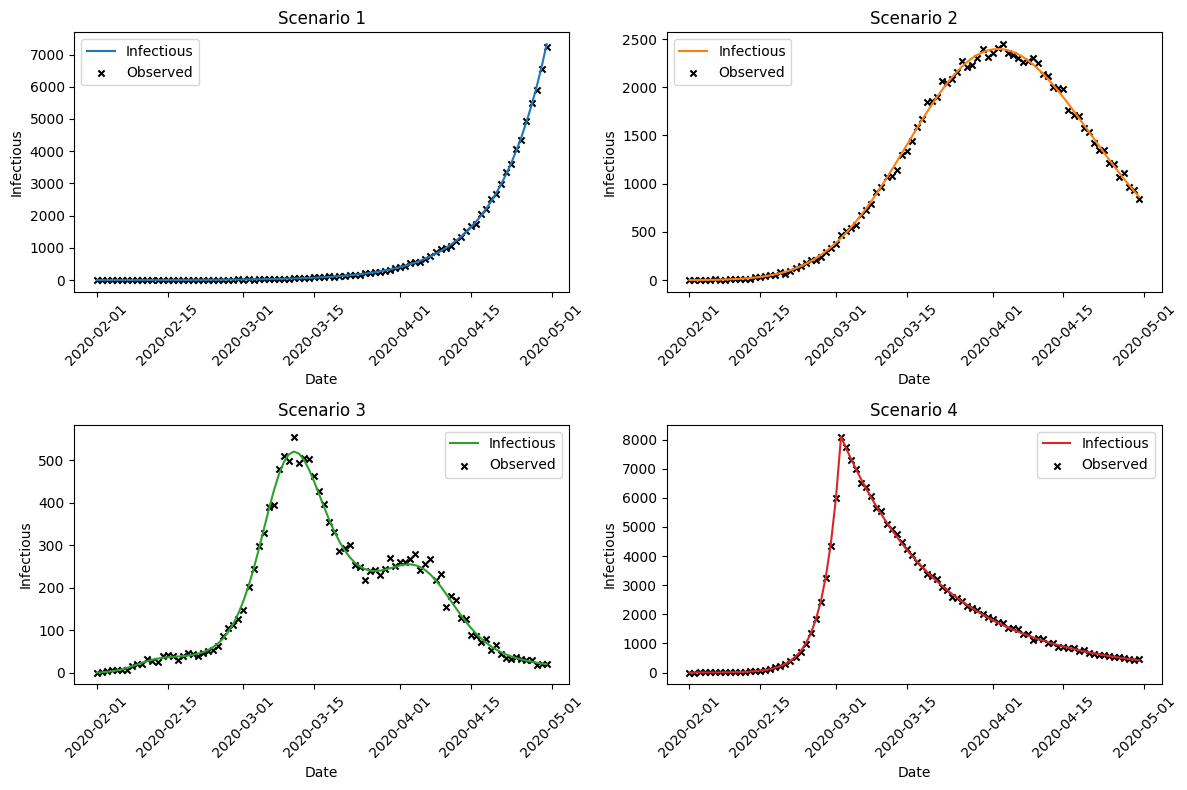

In [2]:

# GPU setup for Google Colab: make sure the runtime is set to a GPU
# (Runtime > Change runtime type > Hardware accelerator > GPU) before running this cell.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
else:
    print("No GPU detected. On Colab: Runtime > Change runtime type > GPU.")

# data location: on Colab, mount Google Drive and read from there;
# locally, just use the data/ folder next to this notebook.
try:
    import google.colab
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/bio-insp/data"
except ImportError:
    DATA_DIR = "data"

# import files

data1 = pd.read_table(f"{DATA_DIR}/S1.txt")
data2 = pd.read_table(f"{DATA_DIR}/S2.txt")
data3 = pd.read_table(f"{DATA_DIR}/S3.txt")
data4 = pd.read_table(f"{DATA_DIR}/S4.txt")


true_beta = pd.read_csv(f"{DATA_DIR}/beta_true_all_scenarios.csv")

# Sir params

N = 56e6  # pop
delta = 1 / 5  # mean reproduction period

# time domain
timespan = pd.to_datetime(data1["Date"]).to_numpy().astype('datetime64[s]')

t0 = 0
tf = len(timespan)

t_data = np.arange(t0, tf)
t_test = np.arange(t0, tf, 0.1)



# infectious data and reproductive number
datasets = [data1, data2, data3, data4]
scenario_names = ["S1", "S2", "S3", "S4"]

I_data = [d["Infectious"].values for d in datasets]
I_obs = [d["I data"].values for d in datasets]
Rt_data = [d["Rt"].values for d in datasets]

# scaling factor (per-scenario, based on each scenario's own observed peak)
#SI = 1e5
SI = [x.max() for x in I_obs]

I_obs_sc = [x / s for x, s in zip(I_obs, SI)]
I_data_sc = [x / s for x, s in zip(I_data, SI)]

t_data_sc = t_data / tf
t_test_sc = t_test / tf



# plot raw data, just to sanity check what's being fed to the networks
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, ax in enumerate(axes):
    ax.plot(timespan, I_data[i], label="Infectious", color=f"C{i}")
    ax.scatter(timespan, I_obs[i], marker='x', s=20, color="black", label="Observed")
    ax.set_title(f"Scenario {i + 1}")
    ax.set_xlabel("Date")
    ax.set_ylabel("Infectious")
    ax.tick_params(axis='x', rotation=45)
    ax.legend()

plt.tight_layout()
plt.show()

# training params
loss_err = 'mse'
optimizer = 'adam'



In [3]:


# NETWORK ARCHITECTURE 
# sciann's "square" output activation just means the last layer's
# output gets squared before being returned, which keeps I(t) and
# Rt(t) non-negative by construction (no need for a softplus/relu
# at the end, the square does the job and stays smooth/differentiable,
# which matters since we need autograd through it for dI/dt).

# FOURIER FEATURE EMBEDDING (for Rt_net only)
#
# plain MLPs suffer from spectral bias (Rahaman et al., 2019): gradient
# descent learns low-frequency components of the target function first
# and struggles with sharp/high-frequency variations. Rt(t) can change
# quickly (interventions, behavioural shifts), so feeding the raw scalar
# t directly into the MLP makes it hard to fit those variations. Mapping
# t through a bank of random sinusoids first (Tancik et al., 2020) gives
# the network high-frequency directions to work with from layer one.
# I_net is left untouched: I(t) is smooth and already fit well by plain
# data regression, so the embedding would only add unneeded capacity/noise.

class FourierFeatures(nn.Module):
    """
    Fixed (non-trainable) random Fourier feature mapping:
    t -> [sin(2*pi*B*t), cos(2*pi*B*t)]. B is sampled once (Gaussian,
    scale sigma) and kept as a buffer, so it is saved/restored with the
    rest of the model but never updated by the optimizer.
    """

    def __init__(self, n_inputs=1, n_frequencies=32, sigma=10.0):
        super().__init__()
        self.register_buffer("B", torch.randn(n_inputs, n_frequencies) * sigma)

    @property
    def out_dim(self):
        return 2 * self.B.shape[1]

    def forward(self, t):
        proj = 2 * torch.pi * (t @ self.B)
        return torch.cat([torch.sin(proj), torch.cos(proj)], dim=-1)


class SquaredMLP(nn.Module):
    """
    Feed-forward network, Softplus hidden activations (smooth, so the
    second derivative needed inside the ODE residual stays well defined),
    output squared at the end to force non-negativity. Optionally embeds
    the input through a FourierFeatures module before the first layer.
    """

    def __init__(self, n_hidden_layers, n_neurons, n_inputs=1, n_outputs=1, fourier=None):
        super().__init__()
        self.fourier = fourier
        layers = []
        in_dim = fourier.out_dim if fourier is not None else n_inputs
        for _ in range(n_hidden_layers):
            layers.append(nn.Linear(in_dim, n_neurons))
            layers.append(nn.Softplus())
            in_dim = n_neurons
        layers.append(nn.Linear(in_dim, n_outputs))
        self.net = nn.Sequential(*layers)

    def forward(self, t):
        x = self.fourier(t) if self.fourier is not None else t
        return self.net(x) ** 2


def make_I_net():
    # matches Isc/Is in the notebook: 4 hidden layers x 50 neurons
    return SquaredMLP(n_hidden_layers=4, n_neurons=50).to(device)


def make_Rt_net(tf, n_frequencies=32, sigma_scale=1.0):
    # matches Rt in the notebook: 4 hidden layers x 100 neurons, plus a
    # Fourier feature embedding of t to counter spectral bias.
    # sigma is tied to tf: t is normalized to [0,1] as t/tf, so a
    # 1-day-scale variation corresponds to a frequency of order tf in
    # normalized units. sigma_scale lets that be tuned without touching tf.
    fourier = FourierFeatures(n_inputs=1, n_frequencies=n_frequencies, sigma=sigma_scale * tf)
    return SquaredMLP(n_hidden_layers=4, n_neurons=100, fourier=fourier).to(device)



# step 1 of the split approach: PURE DATA REGRESSION for I(t)
# 
# no physics here, the network just learns to denoise/interpolate
# the noisy observed infectious curve. this gives a smooth I(t)
# proxy that step 2 will treat as fixed ground truth in the ODE.

def train_data_regression(I_net, t_train, I_train, epochs, batch_size, lr=1e-3):
    opt = optim.Adam(I_net.parameters(), lr=lr)
    mse = nn.MSELoss()
    dataset = torch.utils.data.TensorDataset(t_train, I_train)
    loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)

    history = []
    for epoch in range(epochs):
        running = 0.0
        for tb, Ib in loader:
            opt.zero_grad()
            I_pred = I_net(tb)
            loss = mse(I_pred, Ib)
            loss.backward()
            opt.step()
            running += loss.item() * tb.size(0)
        history.append(running / len(dataset))
    return history



# step 2 of the split approach: PHYSICS INFORMED TRAINING of Rt(t)
# 
# I_net is frozen here (weights copied from step 1, requires_grad=False).
# we only train Rt so that the reduced SIR ODE
#   dI/dt = delta*(Rt-1)*I
# is satisfied at the collocation points. note tf appears because
# t is rescaled to [0,1] (t_sc = t/tf), so d/dt_sc = tf * d/dt.

def train_ode_residual(I_net_frozen, Rt_net, t_collocation, tf, delta, epochs, batch_size, lr=1e-3):
    opt = optim.Adam(Rt_net.parameters(), lr=lr)
    mse = nn.MSELoss()
    dataset = torch.utils.data.TensorDataset(t_collocation)
    loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)

    history = []
    for epoch in range(epochs):
        running = 0.0
        for (tb,) in loader:
            tb = tb.clone().requires_grad_(True)  # need d/dt, so t must track gradients
            opt.zero_grad()

            I_pred = I_net_frozen(tb)
            dI_dt = torch.autograd.grad(
                I_pred, tb,
                grad_outputs=torch.ones_like(I_pred),
                create_graph=True
            )[0]

            Rt_pred = Rt_net(tb)
            residual = dI_dt - tf * delta * (Rt_pred - 1.0) * I_pred  # reduced SIR ODE residual
            loss = mse(residual, torch.zeros_like(residual))

            loss.backward()
            opt.step()
            running += loss.item() * tb.size(0)
        history.append(running / len(dataset))
    return history


In [ ]:


# 
# build and train one split/reduced PINN per scenario
# 

Nc = 6000          # collocation points for the ODE residual, same as the notebook
epochs_data = 1000  # step 1: data regression epochs
batch_data = 10
epochs_ode = 3000   # step 2: physics-informed epochs
batch_ode = 100

results = {}

for i, name in enumerate(scenario_names):

    print(f"\nScenario {name}: training split/reduced PINN (no hospitalization data)")

    torch.manual_seed(34)  # reset seed before each scenario, for reproducibility across runs

    t_data_t = torch.tensor(t_data_sc, dtype=torch.float32, device=device).reshape(-1, 1)
    I_obs_t = torch.tensor(I_obs_sc[i], dtype=torch.float32, device=device).reshape(-1, 1)

    # step 1: train Isc on the noisy observed data only
    I_net = make_I_net()
    t1 = time.time()
    hist_data = train_data_regression(I_net, t_data_t, I_obs_t, epochs_data, batch_data)
    t2 = time.time()
    print(f"  step 1 (data regression) done in {t2 - t1:.1f}s, final loss {hist_data[-1]:.3e}")

    # freeze the I-network: from here on it acts as a fixed, denoised
    # proxy for I(t), exactly like Is.set_weights(Isc_weights) in sciann
    for p in I_net.parameters():
        p.requires_grad_(False)

    # collocation points: t=0 always included, rest sampled uniformly in [0,1]
    t_coll = np.random.uniform(t0 / tf, 1.0, Nc - 1)
    t_coll = np.insert(t_coll, 0, 0.0)
    t_coll_t = torch.tensor(t_coll, dtype=torch.float32, device=device).reshape(-1, 1)

    # step 2: train Rt only, against the frozen I-network, via the ODE residual
    Rt_net = make_Rt_net(tf)
    t1 = time.time()
    hist_ode = train_ode_residual(I_net, Rt_net, t_coll_t, tf, delta, epochs_ode, batch_ode)
    t2 = time.time()
    print(f"  step 2 (ODE residual)   done in {t2 - t1:.1f}s, final loss {hist_ode[-1]:.3e}")

    # predictions on the dense test grid, for plotting
    t_test_t = torch.tensor(t_test_sc, dtype=torch.float32, device=device).reshape(-1, 1)
    with torch.no_grad():
        I_pred_test = I_net(t_test_t).cpu().numpy().flatten() * SI[i]
        Rt_pred_test = Rt_net(t_test_t).cpu().numpy().flatten()

    # predictions on the original data grid, for error metrics against ground truth
    with torch.no_grad():
        I_pred_data = I_net(t_data_t).cpu().numpy().flatten() * SI[i]
        Rt_pred_data = Rt_net(t_data_t).cpu().numpy().flatten()

    I_true = I_data[i]
    Rt_true = Rt_data[i]

    I_err = np.linalg.norm(I_true - I_pred_data, 2) / np.linalg.norm(I_true, 2)
    Rt_err = np.linalg.norm(Rt_true - Rt_pred_data, 2) / np.linalg.norm(Rt_true, 2)
    # last-100-ish-days error, skipping the first 20 points like in the notebook
    # (Rt is typically noisier/less identifiable at the very start of the window)
    Rt_err_tail = np.linalg.norm(Rt_true[20:] - Rt_pred_data[20:], 2) / np.linalg.norm(Rt_true[20:], 2)

    print(f"  I error: {I_err:.3e} | Rt error: {Rt_err:.3e} | Rt error (tail): {Rt_err_tail:.3e}")

    results[name] = {
        "I_net_state": I_net.state_dict(),
        "Rt_net_state": Rt_net.state_dict(),
        "I_pred_test": I_pred_test,
        "Rt_pred_test": Rt_pred_test,
        "I_pred_data": I_pred_data,
        "Rt_pred_data": Rt_pred_data,
        "hist_data": hist_data,
        "hist_ode": hist_ode,
        "I_err": I_err,
        "Rt_err": Rt_err,
        "Rt_err_tail": Rt_err_tail,
    }



Scenario S1: training split/reduced PINN (no hospitalization data)
  step 1 (data regression) done in 24.9s, final loss 1.741e-04
  step 2 (ODE residual)   done in 983.5s, final loss 4.934e-05
  I error: 6.651e-02 | Rt error: 3.161e-01 | Rt error (tail): 1.204e-01

Scenario S2: training split/reduced PINN (no hospitalization data)
  step 1 (data regression) done in 16.8s, final loss 2.893e-04
  step 2 (ODE residual)   done in 975.9s, final loss 1.791e-04
  I error: 1.792e-02 | Rt error: 8.222e-01 | Rt error (tail): 1.578e-02

Scenario S3: training split/reduced PINN (no hospitalization data)
  step 1 (data regression) done in 16.9s, final loss 5.619e-04


In [ ]:

# 
# plot predictions vs ground truth, one row per scenario
# 

fig, axes = plt.subplots(4, 2, figsize=(13, 16))

for i, name in enumerate(scenario_names):
    res = results[name]

    ax_I = axes[i, 0]
    ax_I.plot(t_data, I_data[i], c='r', linewidth=2, label='I (true)')
    ax_I.plot(t_test, res["I_pred_test"], '--', c='k', linewidth=2, label='I (pred)')
    ax_I.scatter(t_data, I_obs[i], marker='x', c='m', s=40, label='samples')
    ax_I.set_title(f"{name} - Infectious")
    ax_I.set_xlabel("days")
    ax_I.legend()

    ax_Rt = axes[i, 1]
    ax_Rt.plot(t_data, Rt_data[i], linewidth=2, label='Rt (true)')
    ax_Rt.plot(t_test, res["Rt_pred_test"], '--', c='k', linewidth=2, label='Rt (pred)')
    ax_Rt.set_title(f"{name} - Reproduction number")
    ax_Rt.set_xlabel("days")
    ax_Rt.legend()

plt.tight_layout()
plt.savefig(f"{DATA_DIR}/pinn_training_predictions.png", dpi=300, bbox_inches="tight")
plt.show()

# save everything (weights + predictions + errors) for later use in Module 3
with open(f"{DATA_DIR}/pinn_results_all_scenarios.pkl", "wb") as f:
    pickle.dump(results, f)



